In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    UpSampling2D,
    Concatenate
)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [5]:
image_path = Path("data/images")
mask_path = Path("data/masks")

image_files = sorted(image_path.glob("*.png"))
mask_files = sorted(mask_path.glob("*.png"))

print("Number of MRI images:", len(image_files))
print("Number of masks:", len(mask_files))

print("\nFirst MRI:", image_files[0])
print("First mask:", mask_files[0])

Number of MRI images: 500
Number of masks: 500

First MRI: data\images\mri_0001.png
First mask: data\masks\mask_0001.png


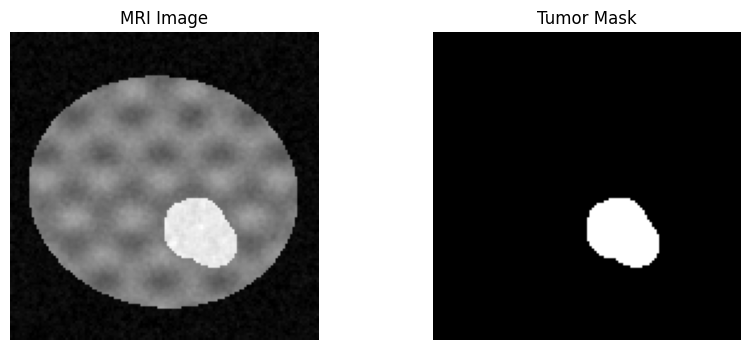

In [6]:
image = Image.open(image_files[0]).convert("L")
mask = Image.open(mask_files[0]).convert("L")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Tumor Mask")
plt.axis("off")

plt.show()


In [7]:
X = []
Y = []

for image_file, mask_file in zip(image_files, mask_files):

    image = Image.open(image_file).convert("L")
    mask = Image.open(mask_file).convert("L")

    X.append(np.array(image))
    Y.append(np.array(mask))

X = np.array(X)
Y = np.array(Y)

print("MRI dataset shape:", X.shape)
print("Mask dataset shape:", Y.shape)

MRI dataset shape: (500, 128, 128)
Mask dataset shape: (500, 128, 128)


In [8]:
# Normalize MRI images from 0-255 to 0-1
X = X.astype("float32") / 255.0

# Convert masks to binary values: 0 or 1
Y = (Y > 127).astype("float32")

# Add channel dimension
X = X[..., np.newaxis]
Y = Y[..., np.newaxis]

print("MRI shape:", X.shape)
print("Mask shape:", Y.shape)
print("MRI value range:", X.min(), "to", X.max())
print("Mask values:", np.unique(Y))

MRI shape: (500, 128, 128, 1)
Mask shape: (500, 128, 128, 1)
MRI value range: 0.0 to 1.0
Mask values: [0. 1.]


In [9]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

print("Training MRI images:", X_train.shape)
print("Testing MRI images:", X_test.shape)

print("Training masks:", Y_train.shape)
print("Testing masks:", Y_test.shape)

Training MRI images: (400, 128, 128, 1)
Testing MRI images: (100, 128, 128, 1)
Training masks: (400, 128, 128, 1)
Testing masks: (100, 128, 128, 1)


In [10]:
def conv_block(x, filters):
    x = Conv2D(filters, 3, activation="relu", padding="same")(x)
    x = Conv2D(filters, 3, activation="relu", padding="same")(x)
    return x


# Input
inputs = Input(shape=(128, 128, 1))

# Encoder
c1 = conv_block(inputs, 32)
p1 = MaxPooling2D((2, 2))(c1)

c2 = conv_block(p1, 64)
p2 = MaxPooling2D((2, 2))(c2)

c3 = conv_block(p2, 128)
p3 = MaxPooling2D((2, 2))(c3)

# Bottleneck
b = conv_block(p3, 256)

# Decoder
u3 = UpSampling2D((2, 2))(b)
u3 = Concatenate()([u3, c3])
c4 = conv_block(u3, 128)

u2 = UpSampling2D((2, 2))(c4)
u2 = Concatenate()([u2, c2])
c5 = conv_block(u2, 64)

u1 = UpSampling2D((2, 2))(c5)
u1 = Concatenate()([u1, c1])
c6 = conv_block(u1, 32)

# Output mask
outputs = Conv2D(1, 1, activation="sigmoid")(c6)

# Create model
model = Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 384)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │    442,496 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_8[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 64, 64,    │          0 │ conv2d_9[0][0]  

 Total params: 1,946,305 (7.42 MB)

 Trainable params: 1,946,305 (7.42 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
history = model.fit(
    X_train,
    Y_train,
    epochs=10,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 63s 3s/step - accuracy: 0.9636 - loss: 0.3610 - val_accuracy: 0.9669 - val_loss: 0.1601
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 65s 3s/step - accuracy: 0.9693 - loss: 0.1262 - val_accuracy: 0.9669 - val_loss: 0.1215
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 58s 3s/step - accuracy: 0.9693 - loss: 0.1093 - val_accuracy: 0.9669 - val_loss: 0.1070
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 60s 3s/step - accuracy: 0.9693 - loss: 0.0917 - val_accuracy: 0.9669 - val_loss: 0.1778
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 61s 3s/step - accuracy: 0.9693 - loss: 0.1005 - val_accuracy: 0.9669 - val_loss: 0.0856
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 58s 3s/step - accuracy: 0.9693 - loss: 0.0829 - val_accuracy: 0.9669 - val_loss: 0.0845
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 59s 3s/step - accuracy: 0.9693 - loss: 0.0841 - val_accuracy: 0.9669 - val_loss: 0.0841
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 70s 4s/step - accuracy: 0.9693 - loss: 0.0748 - val_accuracy: 0.9669 - val_loss:

In [13]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    Y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.9853 - loss: 0.0541
Test Loss: 0.05413758382201195
Test Accuracy: 0.98529052734375


In [14]:
Y_pred = model.predict(X_test)

print("Prediction shape:", Y_pred.shape)

4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step
Prediction shape: (100, 128, 128, 1)


In [15]:
Y_pred_binary = (Y_pred > 0.5).astype("float32")

print("Prediction values:", np.unique(Y_pred_binary))
print("Prediction shape:", Y_pred_binary.shape)

Prediction values: [0. 1.]
Prediction shape: (100, 128, 128, 1)


In [16]:
def dice_score(y_true, y_pred):
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()

    intersection = np.sum(y_true * y_pred)

    dice = (2 * intersection + 1e-7) / (
        np.sum(y_true) + np.sum(y_pred) + 1e-7
    )

    return dice


dice = dice_score(Y_test, Y_pred_binary)

print("Dice Score:", dice)

Dice Score: 0.67267


In [17]:
def iou_score(y_true, y_pred):
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()

    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection

    iou = (intersection + 1e-7) / (union + 1e-7)

    return iou


iou = iou_score(Y_test, Y_pred_binary)

print("IoU Score:", iou)

IoU Score: 0.50678426


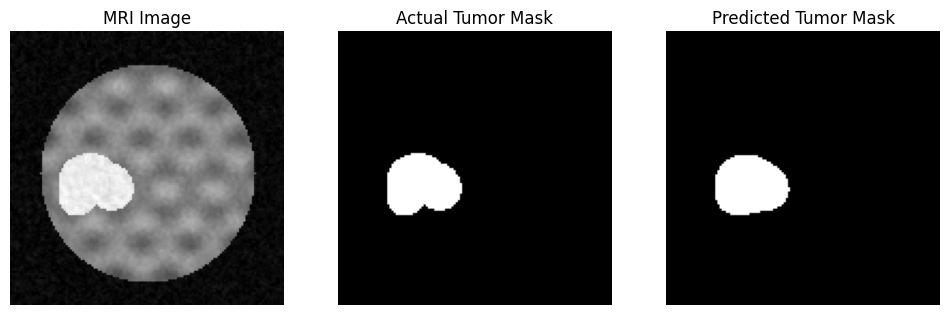

In [18]:
index = 0

plt.figure(figsize=(12, 4))

# Original MRI
plt.subplot(1, 3, 1)
plt.imshow(X_test[index].squeeze(), cmap="gray")
plt.title("MRI Image")
plt.axis("off")

# Actual mask
plt.subplot(1, 3, 2)
plt.imshow(Y_test[index].squeeze(), cmap="gray")
plt.title("Actual Tumor Mask")
plt.axis("off")

# Predicted mask
plt.subplot(1, 3, 3)
plt.imshow(Y_pred_binary[index].squeeze(), cmap="gray")
plt.title("Predicted Tumor Mask")
plt.axis("off")

plt.show()

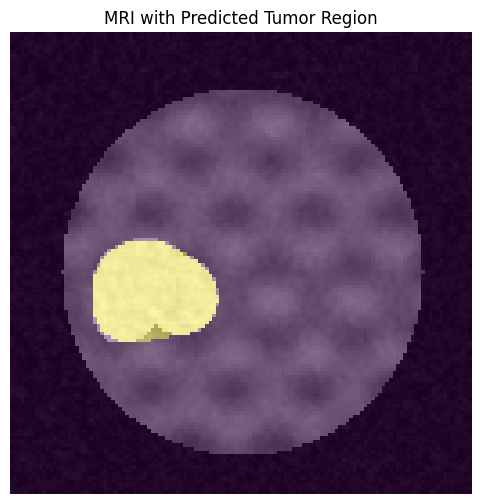

In [19]:
index = 0

mri_image = X_test[index].squeeze()
predicted_mask = Y_pred_binary[index].squeeze()

plt.figure(figsize=(6, 6))

plt.imshow(mri_image, cmap="gray")
plt.imshow(
    predicted_mask,
    alpha=0.4
)

plt.title("MRI with Predicted Tumor Region")
plt.axis("off")

plt.show()

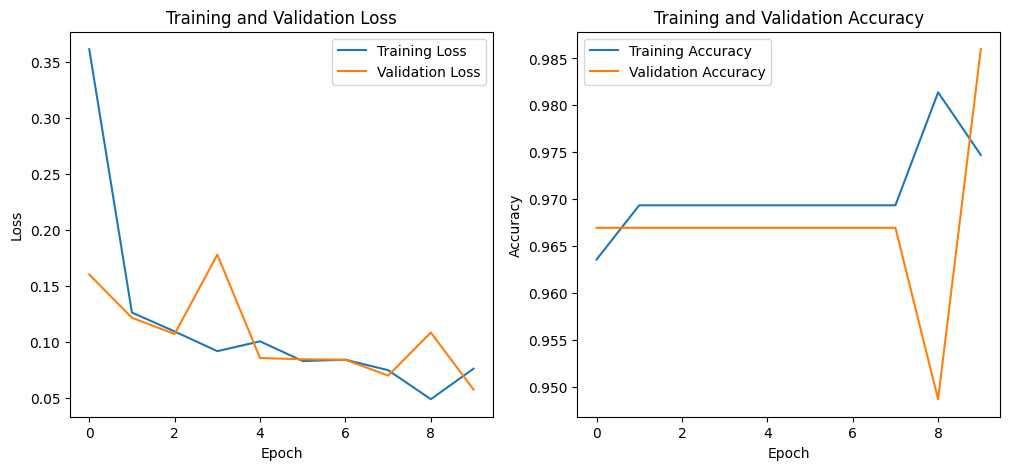

In [20]:
plt.figure(figsize=(12, 5))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Accuracy graph
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

In [21]:
model.save("brain_tumor_unet.keras")

print("U-Net model saved successfully!")

U-Net model saved successfully!


In [22]:
print("========== BRAIN TUMOR SEGMENTATION RESULTS ==========")
print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))
print("Test Accuracy:", round(test_accuracy, 4))
print("Dice Score:", round(dice, 4))
print("IoU Score:", round(iou, 4))
print("Model: U-Net")
print("Input Size: 128 x 128 grayscale")
print("Output: Binary tumor segmentation mask")
print("======================================================")

========== BRAIN TUMOR SEGMENTATION RESULTS ==========
Training Images: 400
Testing Images: 100
Test Accuracy: 0.9853
Dice Score: 0.6727
IoU Score: 0.5068
Model: U-Net
Input Size: 128 x 128 grayscale
Output: Binary tumor segmentation mask
